# 1. Euler's Method

Euler's method is the simplest numerical method for $y' = f(x, y)$, $y(x_0) = y_0$. It is rarely used on its own in practice, but every idea in this chapter (local and global error, order, convergence, stability) can be seen clearly in it first.

Test problem: $y' = x + y$, $y(0) = 1$, exact solution $y = 2e^{x} - x - 1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)

f = lambda x, y: x + y
exact = lambda x: 2 * np.exp(x) - x - 1

## 1.1 Three derivations of the same formula

**(a) From the Taylor series.** Expand the exact solution about $x_n$:

$$y(x_n + h) = y(x_n) + h\,y'(x_n) + \frac{h^2}{2}\,y''(\xi), \qquad \xi \in (x_n, x_{n+1}).$$

Since $y'(x_n) = f(x_n, y(x_n))$, dropping the $h^2$ term gives

$$\boxed{y_{n+1} = y_n + h\,f(x_n, y_n)}$$

**(b) From a difference quotient.** Replace the derivative by the forward difference $y'(x_n) \approx \dfrac{y(x_{n+1}) - y(x_n)}{h}$, set it equal to $f(x_n, y_n)$ and solve for $y_{n+1}$.

**(c) From the integral form.** In $y(x_{n+1}) = y(x_n) + \int_{x_n}^{x_{n+1}} f\,dx$, approximate the integral by the **left rectangle rule**: $h$ times the integrand at the left end.

All three give the same method. Derivation (a) also tells us the size of the error we make in one step: the dropped term $\tfrac{h^2}{2}y''(\xi)$.

**Geometric meaning.** From the current point, walk along the tangent line for a distance $h$. Because the solution curve bends away from its tangent, each step lands slightly off the curve.

**Algorithm**
1. Start with $x_0, y_0$, step size $h$ and number of steps $N$.
2. For $n = 0, 1, \dots, N-1$:
   * compute the slope $k = f(x_n, y_n)$
   * set $y_{n+1} = y_n + hk$ and $x_{n+1} = x_n + h$.

In [2]:
def euler(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        y[i + 1] = y[i] + h * f(x[i], y[i])
        x[i + 1] = x[i] + h
    return x, y

## 1.2 Worked example by hand, $h = 0.1$

| $n$ | $x_n$ | $y_n$ | slope $f(x_n, y_n) = x_n + y_n$ | $y_{n+1} = y_n + 0.1 \times \text{slope}$ | exact $y(x_{n+1})$ | error |
|---|---|---|---|---|---|---|
| 0 | 0.0 | 1.000000 | 1.000000 | 1.100000 | 1.110342 | 0.0103 |
| 1 | 0.1 | 1.100000 | 1.200000 | 1.220000 | 1.242806 | 0.0228 |
| 2 | 0.2 | 1.220000 | 1.420000 | 1.362000 | 1.399718 | 0.0377 |

The error grows every step, because each step starts from an already inaccurate value **and** adds a new error of its own. The code reproduces the table:

In [3]:
x, y = euler(f, 0, 1, 0.1, 3)
for n in range(3):
    print(f"n = {n}:  x = {x[n]:.1f}  y_n = {y[n]:.6f}  slope = {f(x[n], y[n]):.6f}  "
          f"y_(n+1) = {y[n+1]:.6f}  exact = {exact(x[n+1]):.6f}  error = {exact(x[n+1]) - y[n+1]:.4f}")

n = 0:  x = 0.0  y_n = 1.000000  slope = 1.000000  y_(n+1) = 1.100000  exact = 1.110342  error = 0.0103
n = 1:  x = 0.1  y_n = 1.100000  slope = 1.200000  y_(n+1) = 1.220000  exact = 1.242806  error = 0.0228
n = 2:  x = 0.2  y_n = 1.220000  slope = 1.420000  y_(n+1) = 1.362000  exact = 1.399718  error = 0.0377


## 1.3 Pictures of the error

The left plot takes one large step ($h = 0.5$) so the gap between the tangent line and the curve is visible.

The right plot takes four steps with $h = 0.25$ and also draws, through each computed point, the **exact solution curve that passes through it** (dashed). Each step leaves the curve it started on and lands on a new one. Because the solution curves of $y' = x + y$ spread apart (see the [chapter introduction](index.ipynb)), the jumps between curves are amplified as $x$ increases.

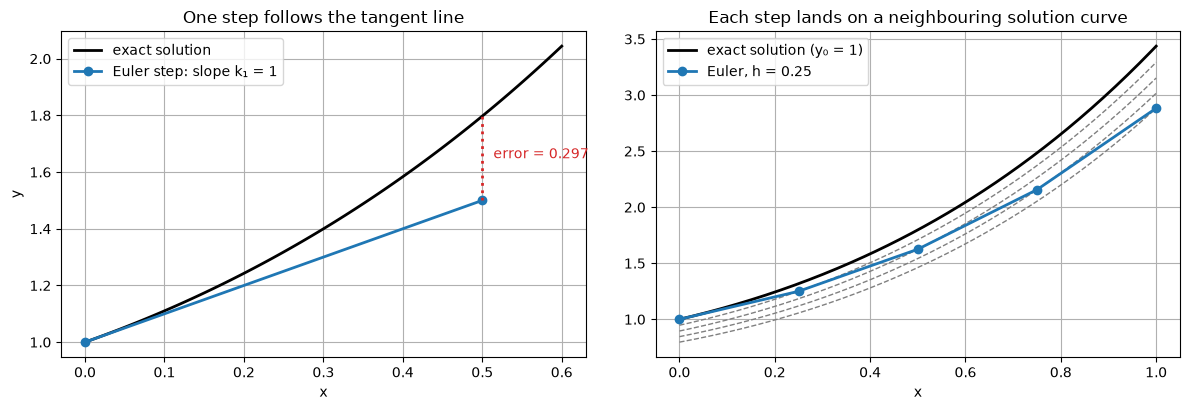

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# One large step
h = 0.5
xf = np.linspace(0, 0.6, 100)
ax = axes[0]
ax.plot(xf, exact(xf), "k", lw=2, label="exact solution")
k1 = f(0, 1)
ax.plot([0, h], [1, 1 + h * k1], "C0o-", lw=2, label=f"Euler step: slope k₁ = {k1:g}")
ax.vlines(h, 1 + h * k1, exact(h), colors="C3", linestyles=":", lw=2)
ax.annotate(f"error = {exact(h) - (1 + h*k1):.3f}", (h, (1 + h*k1 + exact(h)) / 2),
            xytext=(8, 0), textcoords="offset points", color="C3")
ax.set_title("One step follows the tangent line")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend()

# Several steps, with the solution curve through each computed point
ax = axes[1]
h, n = 0.25, 4
xs, ys = euler(f, 0, 1, h, n)
xf = np.linspace(0, 1, 200)
ax.plot(xf, exact(xf), "k", lw=2, label="exact solution (y₀ = 1)")
for xn, yn in zip(xs[1:], ys[1:]):
    C = (yn + xn + 1) * np.exp(-xn)          # y = C e^x - x - 1 passes through (xn, yn)
    ax.plot(xf, C * np.exp(xf) - xf - 1, "--", color="gray", lw=1)
ax.plot(xs, ys, "C0o-", lw=2, label="Euler, h = 0.25")
ax.set_title("Each step lands on a neighbouring solution curve")
ax.set_xlabel("x"); ax.legend()
plt.tight_layout()

## 1.4 Local and global error

* The **local truncation error** (LTE) is the error made in *one* step, starting from the exact value. It is the term we dropped: $\tfrac{h^2}{2}y''(\xi) = O(h^2)$.
  *Check:* here $y'' = 1 + y' = 1 + x + y$, so $y''(0) = 2$ and the predicted first-step error is $\tfrac{0.1^2}{2}\cdot 2 = 0.01$. The actual first-step error is $0.0103$.
* The **global error** is the total error at a fixed point $x = b$ after all $N = (b - x_0)/h$ steps. Roughly $N$ local errors of size $O(h^2)$ add up:

$$\text{global error} \approx N \cdot O(h^2) = \frac{b - x_0}{h}\,O(h^2) = O(h).$$

A method whose global error is $O(h^p)$ has **order $p$**. Euler has order 1: halving $h$ only halves the error, and gaining one more correct digit costs 10 times as many steps.

The argument "$N$ errors of size $h^2$ add up to $h$" ignores that old errors are also amplified by later steps (Section 1.3). The next section makes it rigorous.

## 1.5 A proof that Euler's method converges

**Theorem.** Suppose $f$ satisfies a Lipschitz condition in $y$ with constant $L$, and $|y''(x)| \le M$ on $[x_0, b]$. Then the Euler approximations satisfy

$$|y(x_n) - y_n| \;\le\; \frac{hM}{2L}\left(e^{L(x_n - x_0)} - 1\right).$$

**Proof.** Let $e_n = y(x_n) - y_n$. Taylor's theorem and Euler's formula give

$$
\begin{aligned}
y(x_{n+1}) &= y(x_n) + h f\big(x_n, y(x_n)\big) + \tfrac{h^2}{2}y''(\xi_n),\\
y_{n+1} &= y_n + h f(x_n, y_n).
\end{aligned}
$$

Subtracting,

$$e_{n+1} = e_n + h\Big[f\big(x_n, y(x_n)\big) - f(x_n, y_n)\Big] + \tfrac{h^2}{2}y''(\xi_n).$$

By the Lipschitz condition the bracket is at most $L|e_n|$ in size, so

$$|e_{n+1}| \le (1 + hL)\,|e_n| + \frac{h^2 M}{2}.$$

This says: *the old error is amplified by at most $1 + hL$, and a new local error of at most $h^2M/2$ is added.* Starting from $e_0 = 0$ and applying it repeatedly,

$$|e_n| \le \frac{h^2M}{2}\sum_{j=0}^{n-1}(1 + hL)^j = \frac{h^2M}{2}\cdot\frac{(1 + hL)^n - 1}{hL} = \frac{hM}{2L}\Big((1 + hL)^n - 1\Big).$$

Finally $1 + hL \le e^{hL}$, so $(1 + hL)^n \le e^{nhL} = e^{L(x_n - x_0)}$. $\blacksquare$

**What the theorem says**
* The error bound is proportional to $h$: Euler **converges**, with order 1.
* The factor $e^{L(x_n - x_0)}$ means errors can grow exponentially over long intervals. This is the sensitivity of the ODE itself, not a flaw of the method.
* The bound is a worst case. It is usually pessimistic, but it has the right dependence on $h$.

**Check on the test problem.** $\partial f / \partial y = 1$, so $L = 1$. On $[0, 1]$, $y'' = 2e^{x}$, so $M = 2e$. The bound becomes $h\,e\,(e^{x} - 1)$.

h =   0.1: error at x = 1 is 0.2491,  bound is 0.4671
h =  0.05: error at x = 1 is 0.1300,  bound is 0.2335


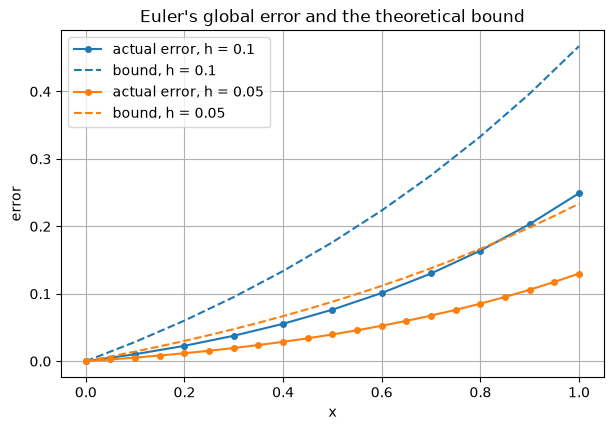

In [5]:
fig, ax = plt.subplots()
for h, c in [(0.1, "C0"), (0.05, "C1")]:
    x, y = euler(f, 0, 1, h, round(1 / h))
    ax.plot(x, exact(x) - y, "o-", color=c, ms=4, label=f"actual error, h = {h}")
    ax.plot(x, h * np.e * (np.exp(x) - 1), "--", color=c, label=f"bound, h = {h}")
    print(f"h = {h:5}: error at x = 1 is {exact(1) - y[-1]:.4f},  bound is {h * np.e * (np.e - 1):.4f}")
ax.set_xlabel("x"); ax.set_ylabel("error")
ax.set_title("Euler's global error and the theoretical bound")
ax.legend();

The bound is about twice the actual error here, and both halve when $h$ is halved.

## 1.6 More worked examples

### Example 1: a decaying solution

$$y' = -2xy, \qquad y(0) = 1, \qquad \text{exact solution } y = e^{-x^2}.$$

Here neighbouring solutions draw together ($\partial f/\partial y = -2x \le 0$), so errors made early on are damped later.

h =   0.2: max |error| on [0, 2] = 0.0751
h =   0.1: max |error| on [0, 2] = 0.0348
h =  0.05: max |error| on [0, 2] = 0.0169


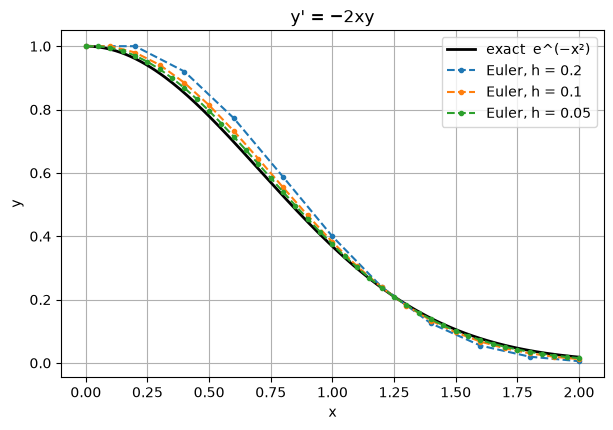

In [6]:
g = lambda x, y: -2 * x * y
g_exact = lambda x: np.exp(-x**2)

xf = np.linspace(0, 2, 200)
plt.plot(xf, g_exact(xf), "k", lw=2, label="exact  e^(−x²)")
for h in [0.2, 0.1, 0.05]:
    x, y = euler(g, 0, 1, h, round(2 / h))
    plt.plot(x, y, "o--", ms=3, label=f"Euler, h = {h}")
    print(f"h = {h:5}: max |error| on [0, 2] = {np.max(np.abs(y - g_exact(x))):.4f}")
plt.xlabel("x"); plt.ylabel("y"); plt.title("y' = −2xy"); plt.legend();

The maximum error roughly halves each time $h$ is halved, as expected for an order 1 method.

### Example 2: a table with the error bound

$$y' = y - x^2 + 1, \qquad y(0) = 0.5, \qquad 0 \le x \le 2, \qquad \text{exact solution } y = (x + 1)^2 - \tfrac{1}{2}e^{x}.$$

Here $L = 1$, and $y'' = 2 - \tfrac{1}{2}e^{x}$, so $|y''| \le \tfrac{1}{2}e^{2} - 2 \approx 1.695 = M$ on $[0, 2]$. With $h = 0.2$ the bound is $\tfrac{0.2 \times 1.695}{2}(e^{x} - 1)$.

In [7]:
p = lambda x, y: y - x**2 + 1
p_exact = lambda x: (x + 1)**2 - 0.5 * np.exp(x)
M = 0.5 * np.exp(2) - 2

h = 0.2
x, y = euler(p, 0, 0.5, h, 10)
print(f"{'x':>4} {'Euler y_n':>11} {'exact':>11} {'error':>9} {'bound':>9}")
for xn, yn in zip(x, y):
    print(f"{xn:4.1f} {yn:11.6f} {p_exact(xn):11.6f} {p_exact(xn) - yn:9.5f} {h * M / 2 * (np.exp(xn) - 1):9.5f}")

   x   Euler y_n       exact     error     bound
 0.0    0.500000    0.500000   0.00000   0.00000
 0.2    0.800000    0.829299   0.02930   0.03752
 0.4    1.152000    1.214088   0.06209   0.08334
 0.6    1.550400    1.648941   0.09854   0.13931
 0.8    1.988480    2.127230   0.13875   0.20767
 1.0    2.458176    2.640859   0.18268   0.29117
 1.2    2.949811    3.179942   0.23013   0.39315
 1.4    3.451773    3.732400   0.28063   0.51771
 1.6    3.950128    4.283484   0.33336   0.66985
 1.8    4.428154    4.815176   0.38702   0.85568
 2.0    4.865785    5.305472   0.43969   1.08264


The actual error stays below the bound at every step, as the theorem guarantees.

### Example 3: Euler does not notice a blow-up

$$y' = y^2, \qquad y(0) = 1, \qquad \text{exact solution } y = \frac{1}{1 - x}.$$

The exact solution becomes infinite at $x = 1$ and does not exist beyond it. $f = y^2$ is not Lipschitz for all $y$, so the convergence theorem does not apply on $[0, 1.5]$.

x = 0.8   Euler y = 3.24
x = 0.9   Euler y = 4.289
x = 1.0   Euler y = 6.129
x = 1.1   Euler y = 9.885
x = 1.2   Euler y = 19.66


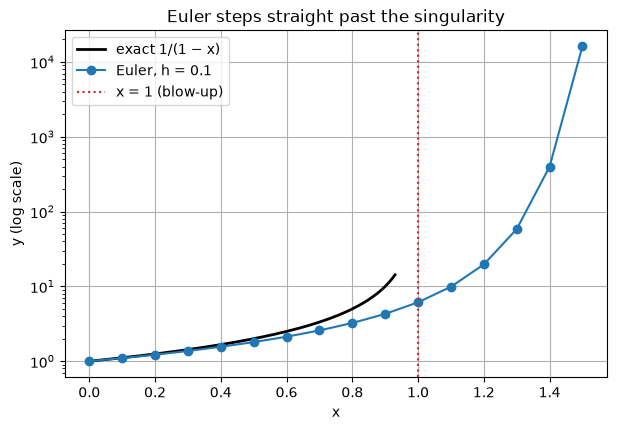

In [8]:
q = lambda x, y: y**2
x, y = euler(q, 0, 1, 0.1, 15)
xf = np.linspace(0, 0.93, 200)
plt.plot(xf, 1 / (1 - xf), "k", lw=2, label="exact 1/(1 − x)")
plt.plot(x, y, "o-", label="Euler, h = 0.1")
plt.axvline(1, color="C3", ls=":", label="x = 1 (blow-up)")
plt.yscale("log"); plt.xlabel("x"); plt.ylabel("y (log scale)")
plt.title("Euler steps straight past the singularity"); plt.legend()
for xn, yn in zip(x[8:13], y[8:13]):
    print(f"x = {xn:.1f}   Euler y = {yn:.4g}")

Euler returns finite numbers for $x > 1$ even though the solution does not exist there. A numerical method only ever sees the values of $f$ at the points it visits. **It cannot warn you that the problem itself has broken down**: that is what the theory in the [chapter introduction](index.ipynb) is for. Watching for values that grow very fast, and halving $h$ to see whether the results settle down, are the practical defences.

## 1.7 Summary

* Euler's method: $y_{n+1} = y_n + h f(x_n, y_n)$. One evaluation of $f$ per step.
* Local truncation error $O(h^2)$, global error $O(h)$: **order 1**.
* Convergence is guaranteed when $f$ is Lipschitz, with error bound $\dfrac{hM}{2L}\big(e^{L(x - x_0)} - 1\big)$.
* It is cheap per step but needs very small steps for good accuracy. The next sections construct methods with higher order.

## Exercises

1. Use Euler with $h = 0.25$ to estimate $y(1)$ for $y' = y$, $y(0) = 1$. Compare with $e$.
2. Show that for the test problem $y' = x + y$, $y(0) = 1$, Euler gives **exactly** $y_n = 2(1 + h)^n - x_n - 1$. Use $\lim_{h \to 0}(1 + h)^{1/h} = e$ to show that $y_n \to y(x_n)$ as $h \to 0$ with $x_n$ fixed.
3. Take three Euler steps of size $h = 0.1$ by hand for $y' = x - y$, $y(0) = 1$. The exact solution is $y = x - 1 + 2e^{-x}$.
4. For $y' = -2xy$, $y(0) = 1$ on $[0, 1]$, find $L$ and $M$ and evaluate the error bound at $x = 1$ for $h = 0.1$. Compare with the actual error.

**Answers**

1. $y_4 = 1.25^4 = 2.441406$; error $e - 2.441406 = 0.2769$.
2. Substitute $y_n = 2(1+h)^n - x_n - 1$ into $y_{n+1} = y_n + h(x_n + y_n)$ and simplify. With $n = x/h$, $(1 + h)^{x/h} = \big((1 + h)^{1/h}\big)^x \to e^{x}$.
3. $y_1 = 0.9$, $y_2 = 0.82$, $y_3 = 0.758$; exact $y(0.3) = 0.781636$, error $0.0236$.
4. $|\partial f/\partial y| = 2x \le 2$, so $L = 2$. $y'' = (4x^2 - 2)e^{-x^2}$ has maximum size $2$ (at $x = 0$), so $M = 2$. The bound is $\frac{0.1 \cdot 2}{2 \cdot 2}(e^{2} - 1) \approx 0.32$, far larger than the actual error, because here the solution curves draw together and the bound assumes the worst case.

The cell below checks the numerical answers.

In [9]:
_, y1 = euler(lambda x, y: y, 0, 1, 0.25, 4)
print(f"1.  y(1) ≈ {y1[-1]:.6f},  error = {np.e - y1[-1]:.4f}")

for h in [0.1, 0.01, 0.001]:
    xs, ys = euler(f, 0, 1, h, round(1 / h))
    print(f"2.  h = {h:6}: max |y_n − (2(1+h)^n − x_n − 1)| = "
          f"{np.max(np.abs(ys - (2 * (1 + h)**np.arange(len(xs)) - xs - 1))):.1e},  error at x = 1: {exact(1) - ys[-1]:.5f}")

_, y3 = euler(lambda x, y: x - y, 0, 1, 0.1, 3)
print(f"3.  y_1, y_2, y_3 = {y3[1:]},  error at 0.3 = {0.3 - 1 + 2 * np.exp(-0.3) - y3[-1]:.4f}")

xs, y4 = euler(g, 0, 1, 0.1, 10)
print(f"4.  actual error at x = 1: {g_exact(1) - y4[-1]:.4f},  bound: {0.1 * 2 / (2 * 2) * (np.exp(2) - 1):.4f}")

1.  y(1) ≈ 2.441406,  error = 0.2769
2.  h =    0.1: max |y_n − (2(1+h)^n − x_n − 1)| = 4.4e-15,  error at x = 1: 0.24908
2.  h =   0.01: max |y_n − (2(1+h)^n − x_n − 1)| = 5.8e-15,  error at x = 1: 0.02694
2.  h =  0.001: max |y_n − (2(1+h)^n − x_n − 1)| = 6.0e-13,  error at x = 1: 0.00272
3.  y_1, y_2, y_3 = [0.9   0.82  0.758],  error at 0.3 = 0.0236
4.  actual error at x = 1: -0.0138,  bound: 0.3195
